In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv('energy_dataset.csv')
pumped_columns = [c for c in df.columns if 'pumped' in c]
column_check = pd.DataFrame({
    'valid': df[pumped_columns].count(),
    'missing': df[pumped_columns].isna().sum()
})
display(column_check)
column = 'generation hydro pumped storage consumption'

,valid,missing
generation hydro pumped storage aggregated,0,35064
generation hydro pumped storage consumption,35045,19


In [13]:
df['local_time'] = pd.to_datetime(df['time'].str.slice(0, 19))
df['hour'] = df['local_time'].dt.hour
df['time_utc'] = pd.to_datetime(df['time'], utc=True)

values = df[column]
quality = pd.Series({
    'rows': len(df),
    'valid_values': values.count(),
    'missing_values': values.isna().sum(),
    'recorded_zero': values.eq(0).sum(),
    'negative_values': values.lt(0).sum()
})
display(quality)
print(f"Missing readings: {values.isna().mean():.4%}")
print(f"Zero share of valid recordings: {values.eq(0).sum() / values.count():.2%}")

rows               35064
valid_values       35045
missing_values        19
recorded_zero      12607
negative_values        0
dtype: int64

Missing readings: 0.0542%
Zero share of valid recordings: 35.97%


In [23]:
hour_groups = df.groupby('hour')[column]
hourly_mean = hour_groups.mean().reindex(range(24))

hourly = hour_groups.agg(
    mean='mean',
    median='median',
    n_valid='count',
    n_rows='size'
).reindex(range(24))
hourly['n_missing'] = hourly['n_rows'] - hourly['n_valid']
display(hourly.round(2))

peak_hour = int(hourly_mean.idxmax())
low_hour = int(hourly_mean.idxmin())
print(f"Highest mean: {peak_hour:02d}:00 = {hourly_mean.loc[peak_hour]:,.2f}")
print(f"Lowest mean: {low_hour:02d}:00 = {hourly_mean.loc[low_hour]:,.2f}")

,mean,median,n_valid,n_rows,n_missing
hour,,,,,
0,434.62,205.0,1461,1461,0
1,762.37,494.0,1461,1461,0
2,1085.82,805.0,1461,1461,0
3,1302.28,1024.5,1460,1461,1
4,1384.48,1102.0,1461,1461,0
5,1278.29,1002.0,1461,1461,0
6,869.54,524.0,1461,1461,0
7,535.51,111.0,1461,1461,0
8,389.75,1.0,1461,1461,0


Highest mean: 04:00 = 1,384.48
Lowest mean: 21:00 = 55.44


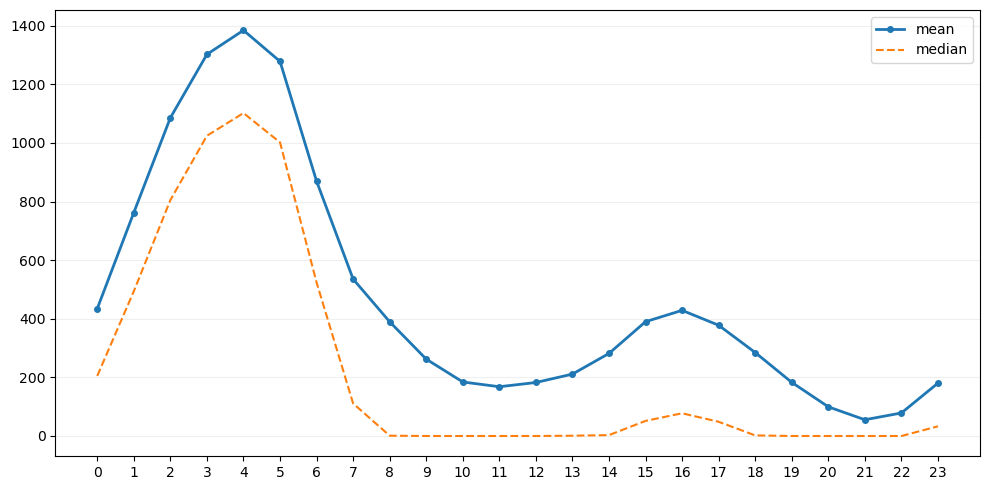

In [33]:



fig, ax =plt.subplots(figsize=(10, 5))
ax.plot(hourly_mean.index, hourly_mean.values, marker='o', markersize=4, linewidth=2, label='mean')
ax.plot(hourly.index, hourly['median'], linestyle='--', label='median')
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.2)
ax.legend(fontsize=10)
fig.tight_layout()
plt.show()

,peak_hour,peak_mean,lower_hour
year,,,
2015,4,1601.95,21
2016,4,1535.00,21
2017,4,1245.20,21
2018,4,1155.34,21


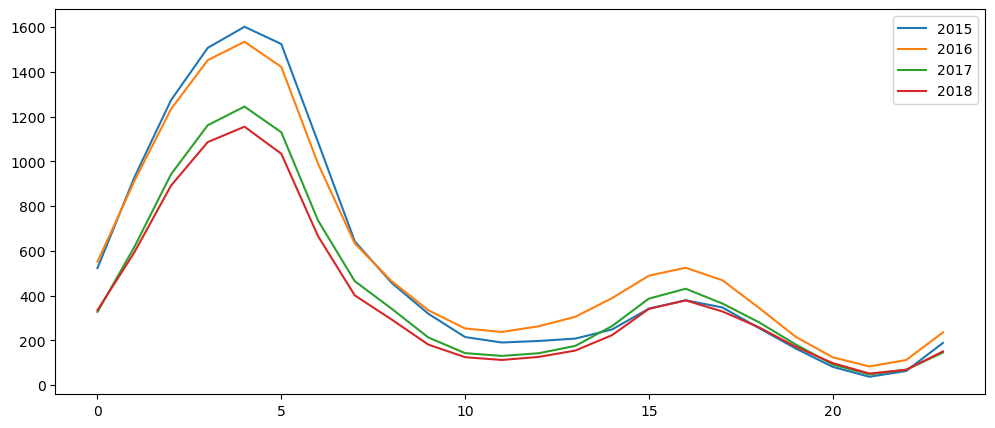

In [45]:
df['year'] = df['local_time'].dt.year
by_year = df.groupby(['hour','year'])[column].mean().unstack('year').reindex(range(24))

year_summary = pd.DataFrame({
    'peak_hour': by_year.idxmax(),
    'peak_mean': by_year.max(),
    'lower_hour':by_year.idxmin()
})
display(year_summary.round(2))

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(by_year.index, by_year)
ax.legend(labels=by_year.columns.astype(str), fontsize=10)